<a href="https://colab.research.google.com/github/johnryantaylor/QCES/blob/main/Project1_numerical_methods.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 1: Heat transport

In this project we will discretize and timestep two systems that describe heat transport. In the first part we will timestep a box model for the Earth's surface temperature with heat buffering provided by the deep ocean. In the second part, we will timestep the one-dimensional diffusion equation which can be used to describe heat moving through a medium (e.g. the ground or still air and water).

Through this project, we will learn how to efficiently timestep ordinary and partial differential equations and examine errors introduced by the numerical discretization. We will also have the chance to explore the timescales and physical processes involved in heat transport in the climate system.

## 1. Climate box model

In this part of the project we will timestep the following box model.

$$ C_s \partial_t T = F(t) - \gamma(T-\theta) $$

$$ C_d \partial_t \theta = \gamma (T-\theta) $$

Here, $T(t)$ represents the global mean surface temperature as a function of time and $\theta(t)$ is the temperature of the deep ocean, both expressed as the difference between the temperature and a pre-industrial equilibrium in units of $^\circ K$. The net surface heat flux, $F(t)$, drives departures from the pre-industrial temperatures. The heat flux between the surface and deep ocean is assumed to be proportional to the difference between the surface and deep ocean temperatures. The constants are the heat capacity of the surface of the Earth, $C_s$, the heat capacity of the deep ocean, $C_d$, and the heat flux coefficient, $\gamma$, all given in units of $W/^\circ K/m^2$. Note that $C_s$ and $C_d$ (as defined in Nicklas et al. 2025) are heat capacities per year; i.e. $1/C_s$ tells us how much the surface temperature would increase if a flux of 1 $W/m^2$ were applied for one year.

This model is inspired by a more complicated version of a two box climate model in the paper referenced below. (Interested students might consider adding some additional features from their model, but this is not required for this project).

*Nicklas, J.M., Fox-Kemper, B. and Lawrence, C., 2025. Efficient Estimation of Climate State and Its Uncertainty Using Kalman Filtering with Application to Policy Thresholds and Volcanism. Journal of Climate, 38(5), pp.1235-1270.*

Below, we start to build code to solve these equations. Execute the code cells below.  In some cases you will be asked to add code.

Student tasks are in [Section 1.1](#section1pt1), [Section 1.2](#section1pt2), and [Section 1.3](#section1pt3).

In [37]:
# Before we start, import necessary libraries. Run this cell first.
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import time

Now, let's define values for the various constants. These values are taken from Nicklas et al., 2025.

In [38]:
C_s = 17 # heat capacity of the Earth's surface (W/m^2/K)
C_d = 156 # heat capacity of the deep ocean (W/m^2/K)
gamma = 0.75 # heat exchange coefficient between surface and deep ocean (W/m^2/K)

Now, let's define a function for F(t), the net surface heat flux (in units of $W/m^2$) that will force our model. This function is here to represent the heat imbalance caused by antropogenic greenhouse gases in the atmosphere. When $F=0$, there is no net surface heat flux. The argument, $t$, is the time in years. We will let $t=0$ denote the start of our additional warming, and we set $F=1$ if $t<200$ years and $F=0$ if $t>200$ years. This corresponds to a very bad-case emissions scenario with an abrupt drop in emissions after 200 years.

In [39]:
def F(t):
    return 1 if t < 200 else 0

Next, set the initial conditions. We will use arrays `T` and `theta`. `T[i]` represents the ith value in the array. We will use `T[0]` and `theta[0]` to hold the initial conditions. Subsequent values, `T[2]`, `T[3]`, etc. will be determined by timestepping the equations. We start by initializing the arrays using numpy and filling them with zeros and then set the initial values (this isn't necessary here since our values are zero anyway, but the code is here to that you can change the initial conditions easily)

In [40]:
Nt = 500 # number of time steps (including the starting point)
T = np.zeros(Nt) # surface temperature array
theta = np.zeros(Nt) # deep ocean temperature array
T[0] = 0 # initial surface temperature anomaly (ºK)
theta[0] = 0 # initial deep ocean temperature anomaly (ºK)

Now, create an array with the time (in years) corresponding to each time index. Also, calculate the timestep, `dt`.

In [41]:
t = np.linspace(0, 500, Nt) # time in years.  This starts at 0 and ends at 500, with Nt total points
dt = t[1] - t[0] # timestep in years

Finally, we are ready to create a for loop to timestep the equations listed at the top of the section.

### 1.1 Student task:
<a id='section1pt1'></a>
Fill in the interior of the for loop to timestep the equations from the start of Section 1 using the Explicit Euler method.

In [42]:
for i in range(0, Nt-1):
    T[i+1] = T[i]+dt*(F(t[i])-gamma*(T[i]-theta[i]))/C_s
    theta[i+1] = theta[i]+dt*(gamma*(T[i]-theta[i]))/C_d

After you are finished, run the cell below to plot the results

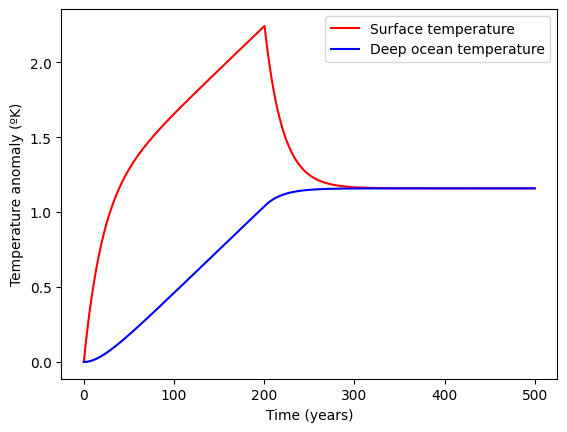

2.2425053229125984


In [43]:
plt.plot(t,T,'r-')
plt.plot(t,theta,'b-')
plt.legend(['Surface temperature','Deep ocean temperature'])
plt.xlabel('Time (years)')
plt.ylabel('Temperature anomaly (ºK)')
plt.show()
print(T[200])

### 1.2 Student task
<a id='section1pt2'></a>
Discuss the rates of change the temperature of the Earth's surface and the deep ocean at the start of the model run.  Can you explain the response of $T$ and $\theta$ to the forcing by defining characteristic timescales from the box model equations?

INSERT DISCUSSION HERE (~1 paragraph)

The change in surface temperature T depends on both the forcing F(t) and the difference between T and $\theta$, whereas change in ocean temperature $\theta$ is not a function of F and only depends on the difference between T and $\theta$. Therefore at t=0, $\theta$ isn't changing and only T increases. Once there is a difference between T and $\theta$, $\theta$ then starts increasing. The $\gamma(T-\theta)$ term is negative for T and positive for $\theta$, so as the difference between T and $\theta$ increases the rate of change of T decreases and rate of change of $\theta$ increases until there is a constant difference between them.

The deep ocean has a much longer characteristic timescale (~232 years) than the surface ocean (around 25 years) so the deep ocean takes much longer to respond to changes in forcing. The timescales can be worked out by $\tau=\frac{C}{\gamma}$, so as the deep ocean has a much higher heat capacity it has a longer timescale. $\gamma$ is the same for both so here the differences in timescale is only due to differences in C_s and C_d

### 1.3 Student task
<a id='section1pt3'></a>
Modify the forcing function, `F(t)` above with 2-3 scenarios of your choice. Plot the temperature response for each scenario and briefly (2-3 sentences each) describe the temperature responses in each scenario. You will need to replicate some of the code blocks above so that you can produce a new set of plots below.

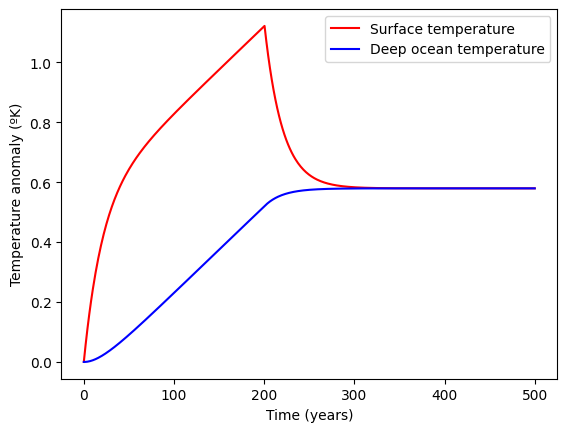

1.1212526614562992


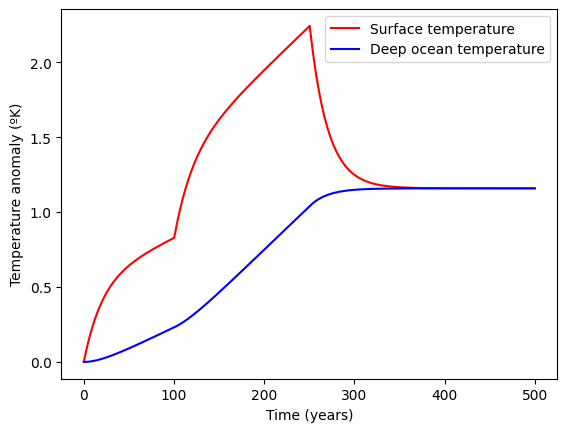

1.9493754071556006
2.2422620066686796


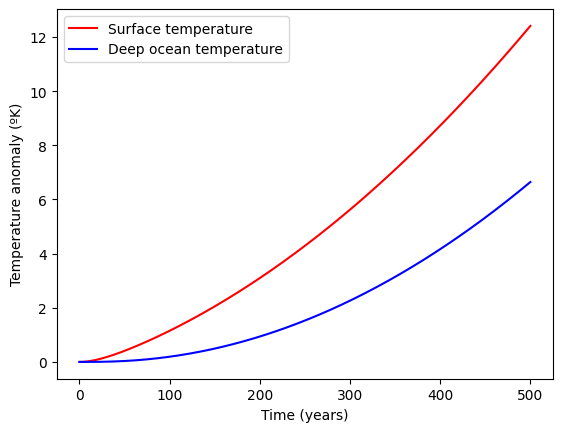

3.105994644511202


In [44]:
# Add code to make plots here

Nt = 500 # number of time steps (including the starting point)
T = np.zeros(Nt) # surface temperature array
theta = np.zeros(Nt) # deep ocean temperature array
T[0] = 0 # initial surface temperature anomaly (ºK)
theta[0] = 0 # initial deep ocean temperature anomaly (ºK)

t = np.linspace(0, 500, Nt) # time in years.  This starts at 0 and ends at 500, with Nt total points
dt = t[1] - t[0] # timestep in years

def run_plot():
  for i in range(0, Nt-1):
      T[i+1] = T[i]+dt*(F(t[i])-gamma*(T[i]-theta[i]))/C_s
      theta[i+1] = theta[i]+dt*(gamma*(T[i]-theta[i]))/C_d
  plt.plot(t,T,'r-')
  plt.plot(t,theta,'b-')
  plt.legend(['Surface temperature','Deep ocean temperature'])
  plt.xlabel('Time (years)')
  plt.ylabel('Temperature anomaly (ºK)')
  plt.show()

def F(t):
    return 0.5 if t < 200 else 0
run_plot()
print(T[200])

def F(t):
    if t<100:
      return 0.5
    elif t<250:
      return 1
    else:
      return 0
run_plot()
print(T[200])
print(T[250])

def F(t):
    return 0.01*t
run_plot()
print(T[200])


In the first plot, F(t) has just been halved from the original plots. In this case, the shape of the graphs is the same but the magnitude of change is exactly halved (the peak value and rates of change of T are exactly half that in the original plots).

In the second plot, F(t) doubles after 100 years, which leads to rates of change of both surface and deep ocean temperature increasing. After the change in F(t), the model runs for another 150 years to a total of 250 years, and the peak surface ocean temperature is then the same as that in the original model, since 100 years at half the rate of change + 50 years at the original rate gives the same total change as 100 years at the original rate of change.

In the third plot, F=0.01t, ie increasing warming forever, so the rate of change of both temperatures is constantly increasing. The temperatures, rates of change and difference between the two temperatures will increase to infinty as t goes to infinity. As the temperature difference increases, the deep will heat up more quickly but it's rate of change will never catch up to that of the surface ocean, due to it's longer residence time.



## 2. Diffusion equation

In this part of the project we will solve the 1-D diffusion equation:

$$ \partial_t c = \kappa \partial_x^2 c $$

We will use second order finite differences to approximate the $x$-derivatives, and we will implement and compare two timestepping methods.

Student tasks are in [Section 2.1](#section2pt1) and [Section 2.2](#section2pt2).

First, let's discretize the second order derivative using finite differences. The function below builds a coefficient matrix, $M$, so that $Mc$ is a discretized version of $\partial^2_x c$, where in our discretized version $c$ is a column vector.

In [45]:
def construct_M(x):
# Build a coefficient matrix, such that M*c is the discrete version of d^2/dx^2(c)
    dx = x[1] - x[0]  # Infer the uniform grid spacing
    Nx = len(x)  # Number of gridpoints
    M = (np.diag(np.ones(Nx-1), -1) - 2*np.diag(np.ones(Nx), 0) + np.diag(np.ones(Nx-1), 1)) / dx**2
    # Impose dc/dx=0 at both ends using ghost points (c[-1]=c[1] and c[Nx]=c[Nx-2])
    M[0, 1] = 2 / dx**2
    M[-1, -2] = 2 / dx**2
    M = sp.csr_matrix(M) # Turn M into a sparse matrix to save memory and improve speed
    return M

Now, define two functions to timestep the diffusion equation. The code below timesteps the diffusion equation using the expicit Euler method. The function takes in a vector of discrete positions, `x`, discrete times, `t`, and the diffusivity, `kappa`. The vectors `x` and `t` dictate the discretization of the problem in space and time, and the grid spacing must be constant in space and time. The boundary conditions are $\partial_x c=0$ at the starting and ending points in `x`.

In [46]:
def EE(x, t, kappa):
# This function timesteps the diffusion equation with homogeneous Neumann boundary conditions
# using the explicit Euler and second order finite difference methods

    start_time = time.time()  # Start a timer

    # Infer the timestep from the time array
    dt = t[1] - t[0]

    M = construct_M(x)  # Construct the coefficient matrix for the second derivative

    # Set the number of gridpoints in x and t
    Nx = len(x); Nt = len(t)

    # Create an empty sparse array to store the solution
    c = np.zeros((Nx, Nt))

    c[:, 0] = set_ics(x, kappa, 10)  # Set the initial condition

    for k in range(1, Nt):  # loop over the number of timesteps
      c[:,k] = c[:,k-1] + dt * kappa * M @ c[:,k-1]

    end_time = time.time()  # Print the elapsed time

    print(f"Explicit Euler method took {end_time - start_time:.2f} seconds")

    return c

Similarly, the function below timesteps the diffusion equation with the Crank-Nicolson method

In [47]:
def CN(x, t, kappa):
# This function timesteps the diffusion equation with homogeneous Neumann boundary conditions
# using the Crank-Nicolson and second order finite difference methods
    start_time = time.time()  # Start a timer

    # Infer the timestep from the time array
    dt = t[1] - t[0]

    M = construct_M(x)  # Construct the coefficient matrix for the second derivative (including the boundary conditions)

    # Set the number of gridpoints in x and t
    Nx = len(x); Nt = len(t)

    A = sp.eye(Nx) - 0.5 * dt * kappa * M  # This matrix appears on the LHS in the C-N scheme
    A_solve = spla.factorized(A.tocsc()) # LU-factorize A (this only needs to be done once)

    # Create an empty sparse array to store the solution
    c = np.zeros((Nx, Nt))

    c[:, 0] = set_ics(x, kappa, 10)  # Set the initial condition

    for k in range(1, Nt): # loop over the number of timesteps
        c[:, k] = A_solve(c[:, k-1] + 0.5 * dt * kappa * (M @ c[:, k-1]))

    end_time = time.time()  # Print the elapsed time

    print(f"Crank-Nicolson method took {end_time - start_time:.2f} seconds")

    return c

Next, create a function to set the initial conditions. The exact solution to the unbounded diffusion equation with a delta function initial condition is:

$$\left(\frac{1}{4\pi\kappa t}\right)^{1/2}e^{-x^2/(4\kappa t)}$$

The function below sets the initial condition by evaluating the exact solution at a given time. Note that it is important that we don't evaluate the exact solution at `t_ic=0` since this will return a delta function which will be undefined on our finite grid. The value of `t_ic` is set within the `EE` and `CN` functions.

In [48]:
# Function to set the initial condition from the exact solution at time t_start
def set_ics(x, kappa, t_ic):
    c_ic = (4*np.pi*kappa*t_ic)**(-0.5)*np.exp(-x**2 / (4*kappa*t_ic))
    return c_ic


Finally, define some parameters and the x and t vectors:

In [49]:
# Defining parameters
kappa = 0.005  # diffusivity

# Timestepping parameters
t_start = 0  # start time (note that this is not the same time used to evaluate the exact solution to set the ICs)
t_end = 10  # end time
Nt = 1000  # number of timesteps

# Size of the physical domain
x_start = -1
x_end = 1
Nx = 100

t = np.linspace(t_start, t_end, Nt)  # Create a vector of times
x = np.linspace(x_start, x_end, Nx)  # Create a vector for x

Run each method once:

In [50]:
# Run the simulations
c_EE = EE(x, t, kappa) # explicit Euler
c_CN = CN(x, t, kappa) # Crank-Nicolson

Explicit Euler method took 0.16 seconds
Crank-Nicolson method took 0.09 seconds


and finally, plot the results side-by-side

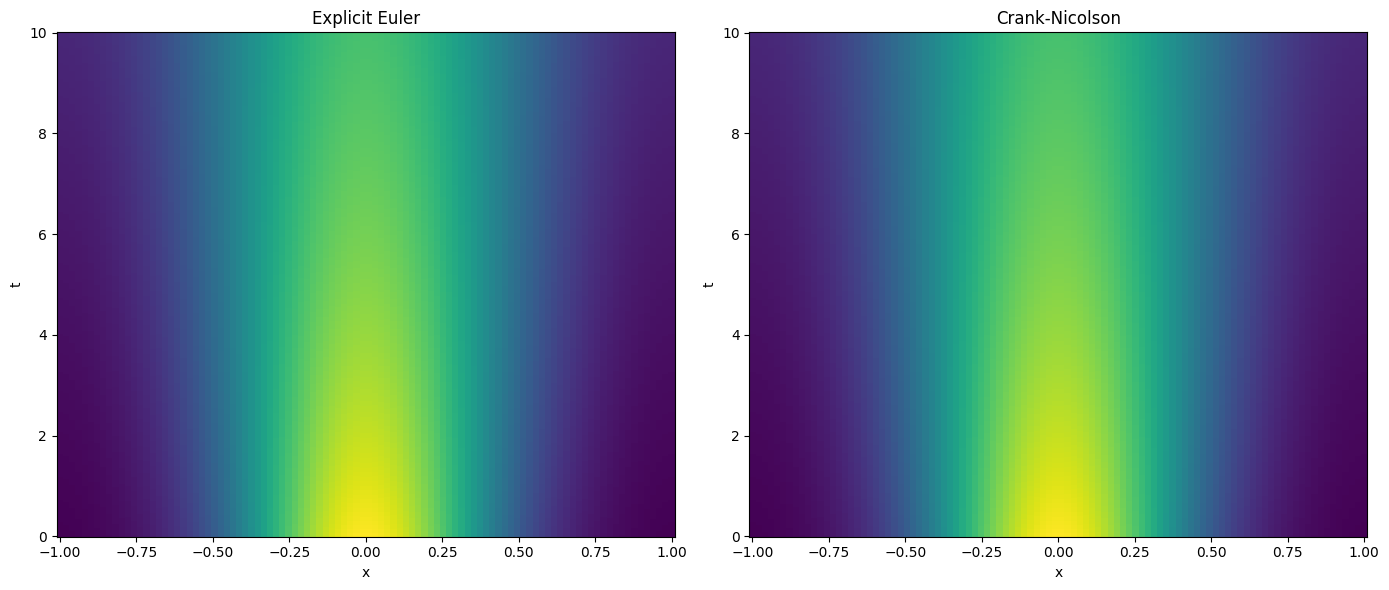

In [51]:
# Plot the results
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.pcolormesh(x, t, c_EE.T, shading='auto')
plt.xlabel('x')
plt.ylabel('t')
plt.title('Explicit Euler')

plt.subplot(1, 2, 2)
plt.pcolormesh(x, t, c_CN.T, shading='auto')
plt.xlabel('x')
plt.ylabel('t')
plt.title('Crank-Nicolson')

plt.tight_layout()
plt.show()

## 2. Student investigation

### 2.1 Stability
<a id='section2pt1'></a>
The explicit Euler and Crank-Nicolson methods have different stability properties. To explore this, try increasing the diffusivity, $\kappa$, and see how each method responds. Discuss your findings below (~2-3 sentences).

INSERT COMMENTS HERE

As $\kappa$ increases, initially the two plots look quite similar, but when $\kappa > 0.02$ the explicit euler solution is unstable and becomes unphysical. This is because, for the explicit euler method, the solution is only stable for low enough values of $\Delta t$ compared to $\kappa$, whereas for Crank-Nicolson the solution is stable for all $\Delta t$ in this case. If you decrease $\Delta t$ here (eg by increasing the number of timesteps Nt to 10000 while keeping the start and end times the same), then the explicit euler becomes stable again even when $\kappa = 0.021$.

### 2.2 Accuracy
<a id='section2pt2'></a>
Next, we will examine the accuracy of the numerical methods used above. In order to do this, it is useful to compare our numerical solutions with the exact solution to the diffusion equation. Below, write code to plot the exact solution and the numerical solution using explicit Euler and Crank-Nicolson at the final time ($t=10$). Note that you can use the exact solution to the diffusion equation in an unbounded domain in $x$ and keep in mind that the exact solution and numerical solutions will differ for later times when boundary effects are felt.

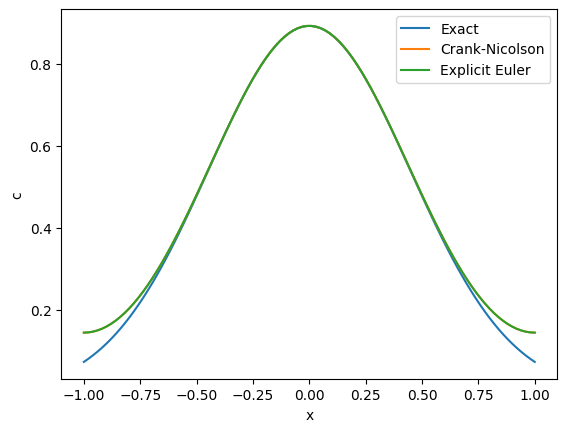

In [52]:
# Add code to plot exact and numerical solutions
# Plot the results
x = np.linspace(-1, 1, 100)  # Create a vector for x
Nx=100
def exact(x, kappa, t):
  t_start_exact = 10  # start time
  t_end_exact = 20  # end time

  # Dynamically determine the number of timesteps as an integer from the length of t
  Nt_local = len(t)
  c_exact_m = np.zeros((Nx, Nt_local))

  # Loop using enumerate to get an integer index (k) and the elapsed time (ti)
  for k, ti in enumerate(t):
    # The exact solution is offset by t_start_exact (10) because the ICs were set at t_ic = 10
    te = t_start_exact + ti
    c_exact_m[:, k] = (4*np.pi*kappa*te)**(-0.5)*np.exp(-x**2 / (4*kappa*te))
  return c_exact_m

# Ensure we reset our global t and Nt values back to their defaults before plotting
Nt = 1000
t = np.linspace(t_start, t_end, Nt)

c_exact = exact(x, kappa, t)
plt.plot(x, c_exact[:, -1], label="Exact")
plt.plot(x, c_CN[:, -1], label="Crank-Nicolson")
plt.plot(x, c_EE[:, -1], label="Explicit Euler")

plt.legend()
plt.xlabel("x")
plt.ylabel('c')
plt.show()


The difference between the exact solution and the numerical approximation can be quantified by various measures of error. The *local error* is the difference between the exact solution and the numerical approximation after one timestep. The *global error* is the difference between the solutions after a fixed amount of time (which includes the accumulation of multiple steps of local error). A method is first order accurate if the global error is linearly proportional to the timestep. A method is second order accurate if the global error varies quadratically with the timestep. Below, calculate and plot the global error for the Explicit Euler and Crank-Nicolson methods and use your results to infer the order of accuracy of each scheme.

PLOT GLOBAL ERROR FOR EACH SCHEME (1-2 figures) AND DISCUSS ORDER OF ACCURACY (2-3 sentences)

Explicit Euler method took 0.11 seconds
dt= 0.01 EE_error= 0.00010887086242994393
Explicit Euler method took 0.12 seconds
dt= 0.01 EE_error= 9.183645621990699e-05
Explicit Euler method took 0.14 seconds
dt= 0.01 EE_error= 7.140043345721381e-05
Explicit Euler method took 0.18 seconds
dt= 0.01 EE_error= 4.643086863787005e-05
Explicit Euler method took 0.29 seconds
dt= 0.0 EE_error= 1.5230966462720374e-05


Crank-Nicolson method took 0.01 seconds
dt= 3.33 CN_error= 0.0036250085332792783
Crank-Nicolson method took 0.01 seconds
dt= 2.5 CN_error= 0.0015535881771677673
Crank-Nicolson method took 0.01 seconds
dt= 2.0 CN_error= 0.0008545883193832542
Crank-Nicolson method took 0.01 seconds
dt= 1.0 CN_error= 0.00014723607652528714
Crank-Nicolson method took 0.01 seconds
dt= 0.67 CN_error= 4.719145231657873e-05
Crank-Nicolson method took 0.01 seconds
dt= 0.5 CN_error= 1.782580136937047e-05
Crank-Nicolson method took 0.01 seconds
dt= 0.4 CN_error= 1.2120898928316025e-05
Crank-Nicolson method took 0

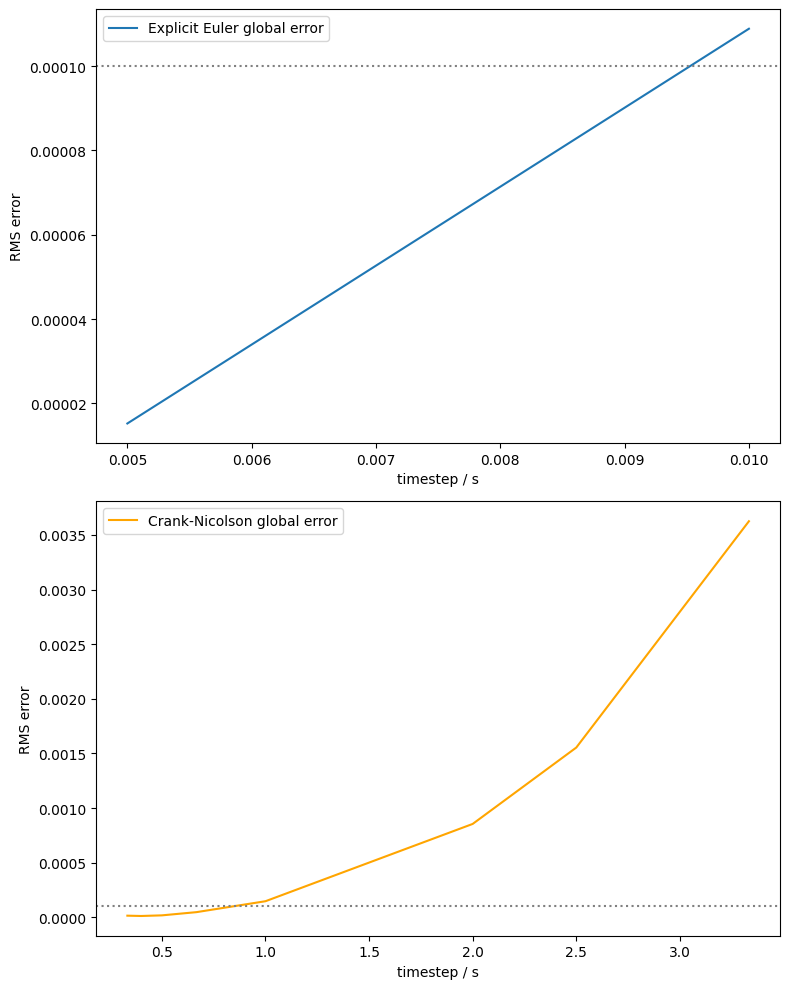

In [56]:
# Add code to plot error here
#DIFFERENT KAPPA
#Increased resolution in x in order to show error specifically from timesteps more clearly
x = np.linspace(-1, 1, 400)  #Increase spatial resolution
kappa=0.001 #changed kappa because I had changed it earlier and forgot about it, and now the timesteps don't work with kappa=0.005 and so keeping it at 0.001 here, the principle is the same
Nx=400
EE_timesteps = [1000,1100,1250,1500,2000]
CN_timesteps=[3,4,5,10,15,20,25,30]

EE_errors = np.zeros(len(EE_timesteps))
CN_errors = np.zeros(len(CN_timesteps))

EE_dts = np.zeros(len(EE_timesteps))
CN_dts = np.zeros(len(CN_timesteps))

for (Nt_index, Nt_val) in enumerate(EE_timesteps):
    Nt_int = int(Nt_val)
    t_grid = np.linspace(t_start, t_end, Nt_int)
    EE_dts[Nt_index]=(t_end-t_start)/Nt_int
    # Run numerical solvers
    c_EE_tmp = EE(x, t_grid, kappa)

    # Evaluate the exact solution at the corresponding temporal grid
    c_exact_tmp = exact(x, kappa, t_grid)

    # Compare at the final timestep [:, -1]
    EE_errors[Nt_index] = np.max(np.abs(c_EE_tmp[:, -1] - c_exact_tmp[:, -1]))
    print("dt=",round(EE_dts[Nt_index],2),"EE_error=", EE_errors[Nt_index])

print("\n")
for (Nt_index, Nt_val) in enumerate(CN_timesteps):
    Nt_int = int(Nt_val)
    t_grid = np.linspace(t_start, t_end, Nt_int)
    CN_dts[Nt_index]=(t_end-t_start)/Nt_int
    # Run numerical solvers
    c_CN_tmp = CN(x, t_grid, kappa)

    # Evaluate the exact solution at the corresponding temporal grid
    c_exact_tmp = exact(x, kappa, t_grid)

    # Compare at the final timestep [:, -1]
    CN_errors[Nt_index] = np.sqrt((np.mean((c_CN_tmp[:, -1] - c_exact_tmp[:, -1])**2)))
    print("dt=",round(CN_dts[Nt_index],2),"CN_error=", CN_errors[Nt_index])

fig, axs = plt.subplots(2, 1, figsize=(8, 10))

axs[0].plot(EE_dts, EE_errors, label="Explicit Euler global error")
axs[0].set_xlabel("timestep / s")
axs[0].set_ylabel("RMS error")
axs[0].legend()

axs[1].plot(CN_dts, CN_errors, label="Crank-Nicolson global error", color="orange")
axs[1].set_xlabel("timestep / s")
axs[1].set_ylabel("RMS error")
axs[1].legend()

axs[0].axhline(y=1e-4,xmin=0,xmax=1,ls=":",color="grey")
axs[1].axhline(y=1e-4,xmin=0,xmax=1,ls=":",color="grey")
plt.tight_layout()
plt.show()

Finally, select a given error tolerance and explore whether explicit Euler or Crank-Nicoslon is more efficient (faster) at generating solutions with error less than your error tolerance. Discuss your conclusion and add supporting figures if necessary.

INSERT DISCUSSION OF ERROR HERE (~1 paragraph).  OPTIONALLY ADD PLOTS BY INSERTING A CODE BLOCK BELOW.

The global error against timestep plot is linear for Explicit Euler and quadratic for Crank-Nicolson, showing that for global error Explicit Euler is 1st order accurate and Crank-Nicolson is 2nd order accurate. For both methods, the error increases as the timestep increases (so temporal resolution decreases), as you would expect. A different range of timesteps have to be used for these plots for Explicit Euler and Crank-Nicolson, because the timesteps that are big enough to show the trend for Crank-Nicolson are big enough that explicit euler is unstable, so smaller timesteps are used here to show the trend in error for explicit euler.

For a tolerance of 1e-4 (shown by grey dashed line in plots), Explicit Euler is much slower and takes 0.11 seconds (with error of 9.2e-5) whereas Crank-Nicolson takes 0.01 seconds (with error of 4.8e-5, but also for every other timestep and error used in this plot). Crank-Nicolson would be slower per timestep (implicit method so more complex calculation than explicit euler) but the same error tolerance can be achieved in far fewer timesteps so it is more efficient overall.

